This notebook accompanies [18-experiment-design](https://xing-phys.github.io/ai-for-physics/18-experiment-design.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Which experiment should we perform next? {#discovery-design}

An experimentalist does more than fit a model after collecting data. They choose the next temperature, pulse sequence, detector angle, or initial state. When experiments are expensive, selection can matter more than a modest improvement in the eventual regression model. The difficulty is that an action may reveal a new regime, refine a parameter already believed to be important, or irreversibly use a limited sample.

We distinguish three goals. **Optimization** seeks a setting with high performance. **Inference** seeks information about an unknown system. **Control** selects a sequence of actions to steer an evolving system. The same apparatus can support all three, but their mathematical objectives differ. This chapter derives a small working example of optimization, connects information to experimental design, and explains what reinforcement learning adds when actions change future states.

## A probabilistic surrogate for an expensive response

Suppose a setting $x$ controls a cooling experiment and $f(x)$ is its expected performance. Measuring $f$ may require an hour. Instead of sampling every setting, we fit a **surrogate**, a cheap approximation used to guide expensive measurements. A useful surrogate includes uncertainty about its own prediction.

A Gaussian process (GP) is a probability distribution over functions defined by a mean function $m(x)$ and covariance kernel $k(x,x')$. For any finite collection $x_1,\ldots,x_n$, the function values have a multivariate Gaussian distribution with means $m(x_i)$ and covariance entries $K_{ij}=k(x_i,x_j)$. A valid kernel must produce a positive-semidefinite matrix for every collection of inputs. One interpretation starts from a finite linear model $f(x)=\phi(x)^Tw$ with $w\sim\mathcal N(0,\Sigma_w)$. Then $k(x,x')=\phi(x)^T\Sigma_w\phi(x')$; kernels generalize this construction without explicitly listing all features.

A common choice is

$$
k(x,x')=a^2\exp[-\|x-x'\|^2/(2\ell^2)].
$$

The amplitude $a$ sets typical variation, and $\ell$ is a correlation length in input space. This kernel assumes a very smooth function; a sharp phase boundary or resonance may require a different kernel or a physically informed change of variables. Distances must be made dimensionless or each input must have a separately specified length scale.

Let observations be $y_i=f(x_i)+\epsilon_i$ with independent Gaussian noise of known variance $\sigma_n^2$. For clarity take $m=0$. At a test point $x_*$, the joint Gaussian covariance of $y$ and $f_*$ is

$$
\begin{pmatrix}K_y&k_*\\k_*^T&k_{**}\end{pmatrix},\quad
K_y=K+\sigma_n^2I,\quad (k_*)_i=k(x_i,x_*).
$$

To derive the conditional distribution, construct $r=f_*-k_*^TK_y^{-1}y$. Its covariance with $y$ is $k_*^T-k_*^TK_y^{-1}K_y=0$. Jointly Gaussian variables with zero covariance are independent. The variance of $r$, obtained by expanding its square, is $k_{**}-k_*^TK_y^{-1}k_*$. Hence

$$
\mu(x_*)=k_*^TK_y^{-1}y,\qquad
s^2(x_*)=k_{**}-k_*^TK_y^{-1}k_*.
$$ 

For nonzero mean, apply these equations to $y-m(X)$ and add $m(x_*)$ back. The variance above concerns the latent response; predicting another noisy measurement adds $\sigma_n^2$. A numerically stable implementation solves linear systems using a Cholesky factor $LL^T=K_y$ rather than explicitly inverting $K_y$. A tiny added diagonal, often called jitter, handles roundoff; it should not be used to hide an inconsistent noise model. These ideas form the standard GP framework [@d-rasmussen2006].

For a worked one-point example, take $k(x,x)=1$, noise variance $0.25$, observation $y=2$, and correlation $k(x,x_1)=r$. Then $\mu=1.6r$ and $s^2=1-0.8r^2$. At $r=1$ the latent variance is $0.2$; far away, at $r=0$, the mean returns to the prior mean zero and variance returns to one. A small posterior variance therefore expresses confidence under the kernel, not an experimental proof that the kernel is correct.

## Bayesian optimization: paying for useful measurements

**Bayesian optimization** repeatedly fits a probabilistic surrogate, chooses an **acquisition function**, measures its selected setting, and updates. An acquisition is a cheap score specifying where to spend the next expensive measurement. For maximizing $f$, an upper-confidence score is

$$
\alpha_{\mathrm{UCB}}(x)=\mu(x)+\beta s(x).
$$

Its first term favors predicted high performance; its second favors uncertain settings. The factor $\beta$ controls exploration. Calling this a confidence bound does not automatically give statistical coverage: rigorous guarantees require assumptions about the function, kernel, noise, and schedule for $\beta$.

Another score is **expected improvement** over a chosen incumbent $f_{\mathrm{best}}$. Under $f(x)\sim\mathcal N(\mu,s^2)$, define $I=\max(f-f_{\mathrm{best}},0)$. With $z=(\mu-f_{\mathrm{best}})/s$,

$$
\mathbb E[I]=(\mu-f_{\mathrm{best}})\Phi(z)+s\varphi(z).
$$

Here $\varphi(z)=e^{-z^2/2}/\sqrt{2\pi}$ and $\Phi(z)=\int_{-\infty}^z\varphi(u)du$. To verify the expression substitute $f=\mu+su$ into the integral over $f>f_{\mathrm{best}}$. The constant term integrates to $(\mu-f_{\mathrm{best}})\Phi(z)$; the remaining integral uses $\varphi'(u)=-u\varphi(u)$ and equals $s\varphi(z)$. At $s=0$, use $\max(\mu-f_{\mathrm{best}},0)$. Under appreciable noise, the largest observed value is an optimistic incumbent; noise-aware acquisitions compare uncertain latent values instead.

The following simulated instrument has a broad background and a narrow resonance. Its domain is already declared physically admissible. The code demonstrates the complete loop with a fixed kernel, a finite candidate set, and a finite budget. It makes no claim that this acquisition is universally best.

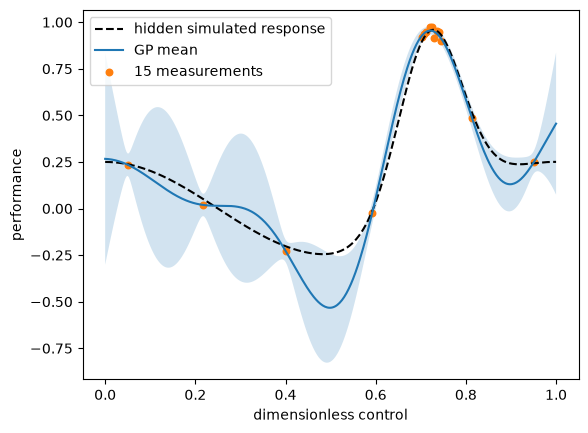

best measured setting: 0.72


In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(1801)

def instrument(x):
    x = np.asarray(x)
    return 0.25*np.cos(2*np.pi*x) + np.exp(-((x-0.72)/0.10)**2)

def kernel(x, z):
    return np.exp(-0.5*((np.asarray(x)[:, None]-np.asarray(z)[None, :])/0.14)**2)

def gp(x, y, grid, noise=0.03):
    L = np.linalg.cholesky(kernel(x, x)+(noise**2+1e-9)*np.eye(len(x)))
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y))
    cross = kernel(x, grid)
    v = np.linalg.solve(L, cross)
    mean = cross.T @ alpha
    var = np.maximum(1.0-(v*v).sum(axis=0), 0)
    return mean, np.sqrt(var)

grid = np.linspace(0, 1, 401)
x = np.array([0.05, 0.40, 0.95])
y = instrument(x)+rng.normal(0, 0.03, len(x))
for step in range(12):
    mean, sd = gp(x, y, grid)
    acquisition = mean+2.0*sd
    # Here we avoid repeats to make the finite-budget illustration simple.
    acquisition[np.min(np.abs(grid[:, None]-x[None, :]), axis=1)<0.004] = -np.inf
    next_x = grid[np.argmax(acquisition)]
    x = np.append(x, next_x)
    y = np.append(y, instrument(next_x)+rng.normal(0, 0.03))
mean, sd = gp(x, y, grid)
assert len(x) == 15 and np.all(sd >= 0)
assert np.max(np.abs(mean)) < 3  # numerical sanity, not a scientific success criterion
plt.plot(grid, instrument(grid), "k--", label="hidden simulated response")
plt.plot(grid, mean, label="GP mean")
plt.fill_between(grid, mean-2*sd, mean+2*sd, alpha=0.2)
plt.scatter(x, y, s=22, label="15 measurements")
plt.xlabel("dimensionless control"); plt.ylabel("performance")
plt.legend(); plt.show()
print("best measured setting:", round(float(x[np.argmax(y)]), 3))

A fair evaluation repeats this campaign across seeds and response families. Compare with random, uniform-grid, and physically motivated scanning strategies under the same total number of measurements. Include failed measurements, initial points, and hyperparameter fitting in the cost. The final best setting should receive independent confirmation; selecting the largest noisy observation creates a selection bias.

## Information seeking is a different objective

Sometimes the goal is a resonance frequency, not a high signal. Let $\theta$ denote the unknown physics and $x$ a chosen experiment. A natural utility is the expected reduction in posterior entropy,

$$
U(x)=H(\theta\mid D)-\mathbb E_{y\mid x,D}H(\theta\mid D,y,x),
$$

where $D$ is existing data and $H(p)=-\int p\log p$ measures uncertainty. Equivalently,

$$
U(x)=\mathbb E_{\theta,y\mid x,D}
\log\frac{p(\theta\mid D,y,x)}{p(\theta\mid D)}.
$$

This follows by substituting the two entropy integrals and using the joint distribution to combine them. It is a mutual information and is nonnegative. It measures expected learning about $\theta$, averaged over possible outcomes, not expected improvement in an apparatus performance metric.

There is a closed form for a local linear Gaussian measurement $y=h_x^T\theta+\epsilon$ with current covariance $S$ and noise variance $\sigma^2$. The updated precision is $S'^{-1}=S^{-1}+h_xh_x^T/\sigma^2$. The entropy of a $p$-dimensional Gaussian is $\tfrac12\log[(2\pi e)^p\det S]$, obtained by averaging its quadratic log density. The determinant identity $\det(I+uv^T)=1+v^Tu$ gives

$$
U(x)=\tfrac12\log\frac{\det S}{\det S'}
=\tfrac12\log\left(1+\frac{h_x^TSh_x}{\sigma^2}\right).
$$

Thus a useful experiment couples strongly to uncertain parameter combinations and has low noise. If its duration is $c(x)$, comparing $U(x)/c(x)$ can be sensible, although sequential resource allocation may require optimizing the full campaign rather than greedy ratios.

**Fisher design** uses a related local approximation. Independent observations add Fisher matrices. Maximizing $\log\det F$ shrinks an approximate uncertainty volume; minimizing $\operatorname{tr}F^{-1}$ targets the sum of variances after choosing parameter units; maximizing the smallest eigenvalue protects the weakest measured direction. These objectives need not choose the same settings.

For $y=A\cos(\omega t)+\epsilon$ with known amplitude and phase, $\partial_\omega y=-At\sin(\omega t)$ and one observation contributes $A^2t^2\sin^2(\omega t)/\sigma^2$. Large $t$ appears attractive locally. Globally, a single late-time observation is consistent with many frequencies because cosine repeats. Early broad exploration resolves these aliases; later observations refine a selected peak. This example explains why a local Fisher calculation can overstate the usefulness of a measurement when the posterior has multiple modes.

## Reinforcement learning when the experiment has memory

If each control changes the next state, a setting cannot be judged in isolation. In a **Markov decision process**, $s_t$ is the state, $a_t$ an action, $P(s_{t+1}\mid s_t,a_t)$ the transition distribution, and $r_t$ a reward. Markov means that the state contains enough history to predict the next transition given the action. Laboratory observations are often only partial measurements of the true state, requiring a history, an inferred latent state, or a probability distribution over states.

A policy $\pi(a\mid s)$ specifies action probabilities. Its discounted return is $G_t=\sum_{k=0}^\infty\gamma^kr_{t+k}$ with $0\leq\gamma<1$. The value $V^\pi(s)=\mathbb E[G_t\mid s_t=s]$ satisfies the **Bellman equation** because $G_t=r_t+\gamma G_{t+1}$:

$$
V^\pi(s)=\sum_a\pi(a\mid s)\sum_{s'}P(s'\mid s,a)
[r(s,a,s')+\gamma V^\pi(s')].
$$

An optimal value replaces the policy average by a maximum over actions. **Value iteration** repeatedly applies that maximum update. For bounded rewards on a finite state space, the update contracts maximum-norm differences by at most $\gamma$, giving a unique fixed point. **Q-learning** instead updates a sampled state-action value,

$$
Q(s,a)\leftarrow Q(s,a)+\eta[r+\gamma\max_{a'}Q(s',a')-Q(s,a)].
$$

This is a stochastic estimate of a Bellman update. Convergence statements for a tabular model require exploration and appropriate decreasing learning rates; they do not transfer automatically to deep networks.

A two-state example makes long-term consequences concrete. An apparatus is either ready $R$ or needs recovery $C$. From $R$, a conservative measurement gives reward $1$ and remains ready. An aggressive measurement gives reward $3$ and enters $C$. From $C$, a mandatory reset gives reward $-1$ and returns to $R$. With $\gamma=0.9$, always conservative has $V_R=1+0.9V_R=10$. Alternating aggressive measurements and resets has $V_R=3+0.9(-1+0.9V_R)$, hence $V_R=2.1/0.19\approx11.05$. If reset instead costs $-3$, the aggressive value becomes $0.3/0.19\approx1.58$ and conservative operation wins. Optimizing immediate reward would miss this reversal.

## From algorithms to an autonomous laboratory

A practical loop includes state estimation, action selection, hardware execution, characterization, data validation, and updating. Physical restrictions belong in the action set and supervisory control, including actuator ranges, rate limits, interlocks, and recovery procedures. Penalizing a dangerous action in a reward does not guarantee it will never be tried. An independently enforced constraint can. Exploration on a validated simulator can reduce costly hardware trials, but simulator errors must be included in deployment validation.

Experiments establish that such loops can work in important restricted settings. Deep reinforcement learning was demonstrated for magnetic plasma control [@d-degrave2022], and a later experiment targeted tearing-instability avoidance using a learned dynamics model [@d-seo2024]. These results are evidence for specific control tasks and operating regimes; neither establishes an all-purpose fusion controller. In materials synthesis, A-Lab integrated recipe proposals, robotic synthesis, characterization, and active learning [@d-szymanski2023]. Its updated article and 2026 correction are a useful reminder that a functioning autonomous workflow and a validated claim of new materials are separate achievements [@d-alabcorrection2026].

A less dramatic but pervasive challenge is **drift**: the apparatus response changes with time. A laser alignment moves; a source depletes; a detector gain changes. A stationary GP treats all repeated measurements as samples of one fixed function and may become falsely confident. Repeated reference measurements expose drift. A time-dependent kernel, a rolling data window, or explicit calibration-state inference can model it, but each needs validation. Do not confuse an algorithm successfully tracking drift with learning a new physical law.

A complete campaign records the proposed action, executed action, timestamp, calibration state, raw and processed observations, processing code version, failed outcomes, acquisition score, and reason for stopping. Selecting only successful runs biases both the scientific inference and the next policy. Appropriate stopping rules include exhausted budget, no remaining feasible experiments, a target uncertainty, or a separately confirmed performance threshold.

## Exercises and worked answers

1. Derive the GP posterior at the training point for one observation with arbitrary prior variance $a^2$ and noise variance $\sigma_n^2$. Explain both limiting noise cases.
2. Suppose one measurement has $h_1=(1,0)$ and another $h_2=(0,1)$, with unit noise. Starting from $S=\operatorname{diag}(9,1)$, which has larger information gain? What happens after observing the first direction nine times?
3. Change the simulated resonance width from $0.10$ to $0.02$. Design a fair test of kernel mismatch.
4. Recalculate the two-state control example at $\gamma=0$, and explain what physical preferences have changed.

**Answers.** In exercise 1, $\mu=a^2y/(a^2+\sigma_n^2)$ and $s^2=a^2\sigma_n^2/(a^2+\sigma_n^2)$. As noise vanishes the function value is determined; as noise diverges the observation adds no information. In exercise 2 the gains are $\tfrac12\log10$ and $\tfrac12\log2$. After nine measurements in direction one its variance is $(1/9+9)^{-1}=9/82<1$, so the second direction is preferred. Exercise 3 requires repeated campaigns with unchanged budgets, comparison to uniform and random scans, and both fixed-kernel and refitted-kernel variants; a fortunate seed does not establish robustness. At $\gamma=0$ only the immediate reward matters, so the aggressive action wins despite future reset costs. Discounting is a scientific or operational choice, not merely an optimizer setting.